In [1]:
import sys
!{sys.executable} -m pip install opencv-python


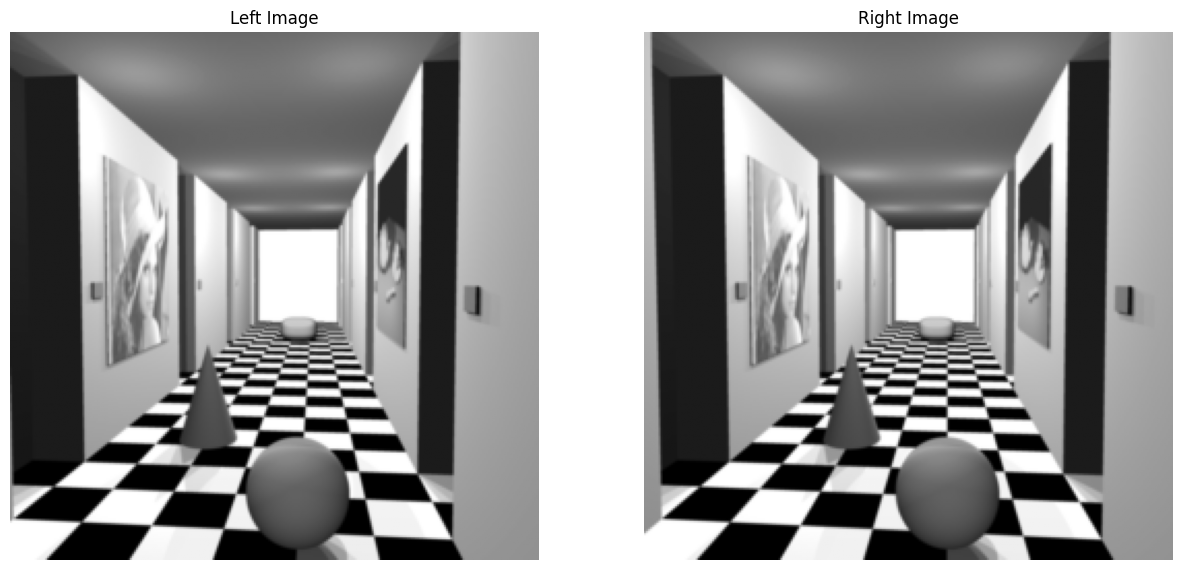

Both images have the same dimensions: (256, 256)


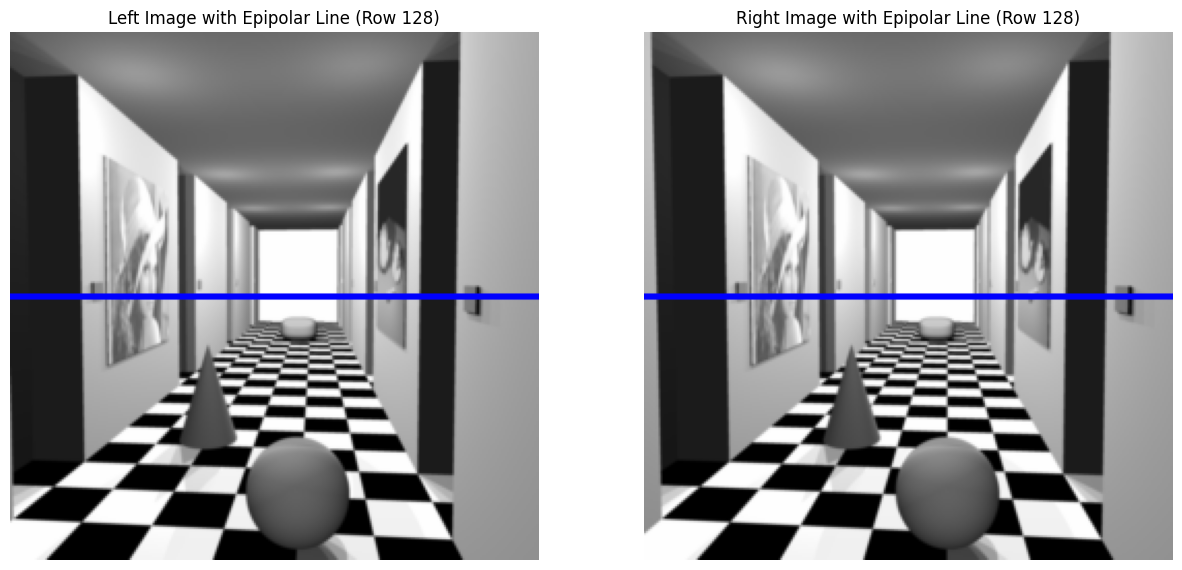

Highlighted horizontal epipolar line at row: 128


In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


img_left_path = '/content/Ir.jpg'
img_right_path = '/content/Il.jpg'

img_left = cv2.imread(img_left_path, cv2.IMREAD_GRAYSCALE)
img_right = cv2.imread(img_right_path, cv2.IMREAD_GRAYSCALE)

if img_left is None:
    print(f"Error: Left image not loaded from {img_left_path}")
if img_right is None:
    print(f"Error: Right image not loaded from {img_right_path}")


plt.figure(figsize=(15, 7))
plt.subplot(1, 2, 1)
plt.imshow(img_left, cmap='gray')
plt.title('Left Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_right, cmap='gray')
plt.title('Right Image')
plt.axis('off')
plt.show()


if img_left.shape == img_right.shape:
    print(f"Both images have the same dimensions: {img_left.shape}")
else:
    print(f"Image dimensions differ: Left {img_left.shape}, Right {img_right.shape}")

    if img_left.shape[0] < img_right.shape[0] or img_left.shape[1] < img_right.shape[1]:
        img_left = cv2.resize(img_left, (img_right.shape[1], img_right.shape[0]), interpolation=cv2.INTER_AREA)
        print(f"Resized Left Image to: {img_left.shape}")
    elif img_right.shape[0] < img_left.shape[0] or img_right.shape[1] < img_left.shape[1]:
        img_right = cv2.resize(img_right, (img_left.shape[1], img_left.shape[0]), interpolation=cv2.INTER_AREA)
        print(f"Resized Right Image to: {img_right.shape}")

selected_row = img_left.shape[0] // 2

img_left_epipolar = cv2.cvtColor(img_left, cv2.COLOR_GRAY2BGR)
img_right_epipolar = cv2.cvtColor(img_right, cv2.COLOR_GRAY2BGR)


cv2.line(img_left_epipolar, (0, selected_row), (img_left.shape[1], selected_row), (0, 0, 255), 2)
cv2.line(img_right_epipolar, (0, selected_row), (img_right.shape[1], selected_row), (0, 0, 255), 2)

plt.figure(figsize=(15, 7))
plt.subplot(1, 2, 1)
plt.imshow(img_left_epipolar)
plt.title(f'Left Image with Epipolar Line (Row {selected_row})')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_right_epipolar)
plt.title(f'Right Image with Epipolar Line (Row {selected_row})')
plt.axis('off')
plt.show()

print(f"Highlighted horizontal epipolar line at row: {selected_row}")


## Lab Task 2: Implement SSD-based Stereo Matching and Generate Disparity Maps


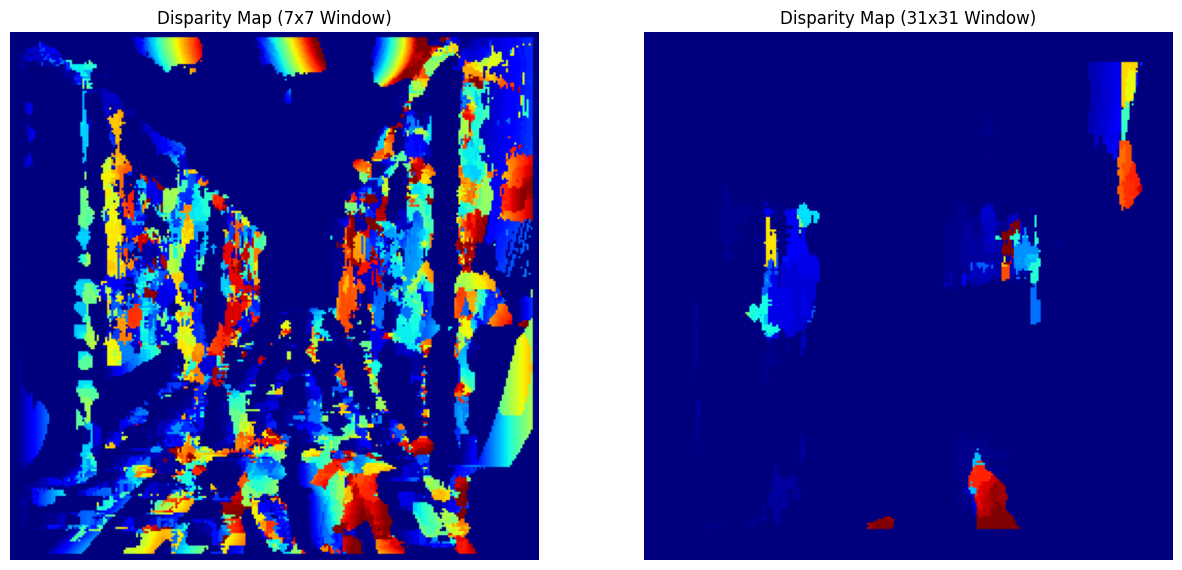

Comparison of window sizes:
  - Smaller window (7x7): Captures finer details but is more susceptible to noise and may produce more 'holes' in textureless regions.
  - Larger window (31x31): Provides smoother disparity maps and is more robust to noise, but it can blur details and may struggle with depth discontinuities (e.g., edges of objects).


In [4]:

def ssd_stereo_matching(img_left, img_right, window_size, max_disparity):
    h, w = img_left.shape
    disparity_map = np.zeros((h, w), dtype=np.uint8)

    half_window = window_size // 2

    for r in range(half_window, h - half_window):
        for c_left in range(half_window, w - half_window):
            best_ssd = float('inf')
            best_d = 0


            window_left = img_left[r - half_window : r + half_window + 1,
                                   c_left - half_window : c_left + half_window + 1]


            for d in range(max_disparity):
                c_right = c_left - d
                if c_right - half_window < 0 or c_right + half_window + 1 > w:
                    continue


                window_right = img_right[r - half_window : r + half_window + 1,
                                        c_right - half_window : c_right + half_window + 1]


                ssd = np.sum((window_left - window_right)**2)

                if ssd < best_ssd:
                    best_ssd = ssd
                    best_d = d
            disparity_map[r, c_left] = best_d * (255 / max_disparity)

    return disparity_map

max_disparity = 64


window_size_7x7 = 7
disparity_7x7 = ssd_stereo_matching(img_left, img_right, window_size_7x7, max_disparity)


window_size_31x31 = 31
disparity_31x31 = ssd_stereo_matching(img_left, img_right, window_size_31x31, max_disparity)


plt.figure(figsize=(15, 7))
plt.subplot(1, 2, 1)
plt.imshow(disparity_7x7, cmap='jet')
plt.title('Disparity Map (7x7 Window)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(disparity_31x31, cmap='jet')
plt.title('Disparity Map (31x31 Window)')
plt.axis('off')
plt.show()

print("Comparison of window sizes:")
print("  - Smaller window (7x7): Captures finer details but is more susceptible to noise and may produce more 'holes' in textureless regions.")
print("  - Larger window (31x31): Provides smoother disparity maps and is more robust to noise, but it can blur details and may struggle with depth discontinuities (e.g., edges of objects).")


## Lab Task 3: Calculate Depth Map


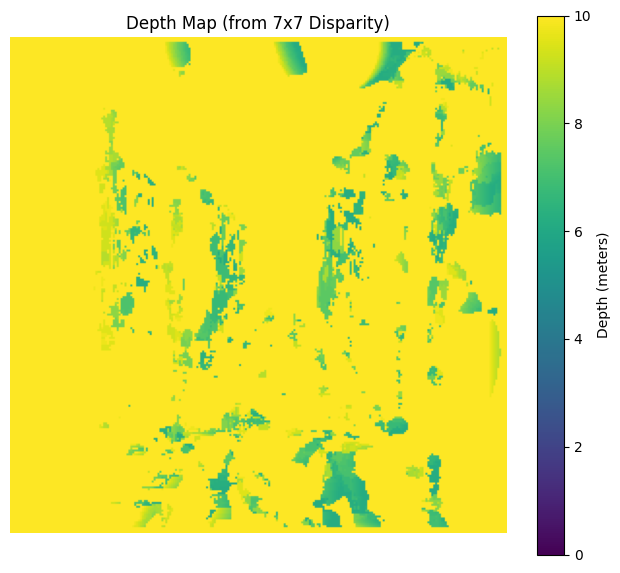

In [7]:
# Given parameters
B = 0.54  # baseline in meters
f = 721.5 # focal length in pixels

# Ensure disparity is not zero to avoid division by zero
# We'll use the disparity_7x7 map as requested.
# Disparity values from the SSD function are normalized to 0-255.
# We need to convert them back to original disparity values for calculation.
# The actual disparity in pixels ranges from 0 to max_disparity

disparity_pixels = disparity_7x7 / (255 / max_disparity) # Convert back to pixel disparity
disparity_pixels[disparity_pixels == 0] = 0.1 # Replace zero disparities with a small value to prevent division by zero

# Calculate depth map: Z = fB / d
depth_map = (f * B) / disparity_pixels

# Display the resulting depth map
plt.figure(figsize=(8, 7))
plt.imshow(depth_map, cmap='viridis', vmin=0, vmax=10) # Adjust vmax for better visualization if needed
plt.colorbar(label='Depth (meters)')
plt.title('Depth Map (from 7x7 Disparity)')
plt.axis('off')
plt.show()


## Lab Task 4: Investigate the Effect of Baseline, Focal Length, and Disparity on Depth


In [8]:
def calculate_depth(focal_length, baseline, disparity):
    if disparity == 0:
        return float('inf') # Infinite depth for zero disparity
    return (focal_length * baseline) / disparity

# --- Investigate effect of Baseline (B) ---
f_fixed = 721.5 # pixels
d_fixed = 10    # pixels

baselines = [0.2, 0.54, 1.0] # meters
print("--- Effect of Baseline (B) ---")
for b in baselines:
    depth = calculate_depth(f_fixed, b, d_fixed)
    print(f"Focal Length = {f_fixed} px, Baseline = {b} m, Disparity = {d_fixed} px -> Depth = {depth:.2f} m")
print("Observation: As the baseline increases, the calculated depth increases proportionally, assuming fixed focal length and disparity.")
print()

# --- Investigate effect of Focal Length (f) ---
b_fixed = 0.54 # meters
d_fixed = 10   # pixels

focal_lengths = [300, 721.5, 1000] # pixels
print("--- Effect of Focal Length (f) ---")
for f_val in focal_lengths:
    depth = calculate_depth(f_val, b_fixed, d_fixed)
    print(f"Focal Length = {f_val} px, Baseline = {b_fixed} m, Disparity = {d_fixed} px -> Depth = {depth:.2f} m")
print("Observation: As the focal length increases, the calculated depth increases proportionally, assuming fixed baseline and disparity.")
print()

# --- Investigate effect of Disparity (d) ---
f_fixed = 721.5 # pixels
b_fixed = 0.54  # meters

disparities = [5, 10, 20] # pixels
print("--- Effect of Disparity (d) ---")
for d_val in disparities:
    depth = calculate_depth(f_fixed, b_fixed, d_val)
    print(f"Focal Length = {f_fixed} px, Baseline = {b_fixed} m, Disparity = {d_val} px -> Depth = {depth:.2f} m")
print("Observation: As the disparity increases, the calculated depth decreases. They have an inverse relationship. A larger disparity means the object is closer.")
print()

print("Summary: Depth is directly proportional to focal length and baseline, and inversely proportional to disparity. This means objects appear closer (smaller disparity, larger depth) with smaller focal lengths or baselines, and further away (larger disparity, smaller depth) with larger focal lengths or baselines.")


--- Effect of Baseline (B) ---
Focal Length = 721.5 px, Baseline = 0.2 m, Disparity = 10 px -> Depth = 14.43 m
Focal Length = 721.5 px, Baseline = 0.54 m, Disparity = 10 px -> Depth = 38.96 m
Focal Length = 721.5 px, Baseline = 1.0 m, Disparity = 10 px -> Depth = 72.15 m
Observation: As the baseline increases, the calculated depth increases proportionally, assuming fixed focal length and disparity.

--- Effect of Focal Length (f) ---
Focal Length = 300 px, Baseline = 0.54 m, Disparity = 10 px -> Depth = 16.20 m
Focal Length = 721.5 px, Baseline = 0.54 m, Disparity = 10 px -> Depth = 38.96 m
Focal Length = 1000 px, Baseline = 0.54 m, Disparity = 10 px -> Depth = 54.00 m
Observation: As the focal length increases, the calculated depth increases proportionally, assuming fixed baseline and disparity.

--- Effect of Disparity (d) ---
Focal Length = 721.5 px, Baseline = 0.54 m, Disparity = 5 px -> Depth = 77.92 m
Focal Length = 721.5 px, Baseline = 0.54 m, Disparity = 10 px -> Depth = 38.96 